In [299]:
# Import Modules
import pandas
import matplotlib
from datetime import datetime
import numpy as np
from tqdm.auto import tqdm

Importing dynamic utilization data for 2025

In [300]:
# Load 2025 Electricity spot price data
with open("spot_price.csv") as f:
    spotprice_contents = pandas.read_csv(f, sep=",")

    for i in range(len(spotprice_contents)):
        spotprice_contents.loc[i, "Aika"] = datetime.strptime(spotprice_contents.loc[i, "Aika"], "%d/%m/%Y %H.%M.%S")

    spotprice_contents["Hinta (snt/kWh)"] = spotprice_contents["Hinta (snt/kWh)"].astype(dtype=float)    


# Load 2025 Helen open data District Heating consumption & parse data
with open("helen_open_dh_data_2025.csv") as f:
    DH_contents = pandas.read_csv(f, sep=";")

    for i in range(len(DH_contents)):
        DH_contents.loc[i, "dh_MWh"] = DH_contents.loc[i, "dh_MWh"].replace(",", ".")
        DH_contents.loc[i, "datetime_utc"] = datetime.strptime(DH_contents.loc[i, "datetime_utc"], "%d.%m.%Y %H:%M")

    DH_contents["dh_MWh"] = DH_contents["dh_MWh"].astype(dtype=float)

print(spotprice_contents)
print(DH_contents)

                      Aika  Hinta (snt/kWh)
0      2025-01-01 00:00:00            0.503
1      2025-01-01 00:15:00            0.503
2      2025-01-01 00:30:00            0.503
3      2025-01-01 00:45:00            0.503
4      2025-01-01 01:00:00            0.609
...                    ...              ...
35035  2025-12-31 22:45:00           12.940
35036  2025-12-31 23:00:00           18.436
35037  2025-12-31 23:15:00           13.805
35038  2025-12-31 23:30:00           13.406
35039  2025-12-31 23:45:00           12.452

[35040 rows x 2 columns]
             datetime_utc       dh_MWh
0     2025-01-01 00:00:00  1079.311066
1     2025-01-01 01:00:00  1080.117903
2     2025-01-01 02:00:00  1068.299144
3     2025-01-01 03:00:00  1087.349176
4     2025-01-01 04:00:00  1149.986834
...                   ...          ...
8755  2025-12-31 19:00:00  1569.255790
8756  2025-12-31 20:00:00  1548.119433
8757  2025-12-31 21:00:00  1529.536736
8758  2025-12-31 22:00:00  1520.535705
8759  2025-12-31 

In [301]:
# Normalize DH consumption to share of heat consumption for the datacenter
peak = max(DH_contents["dh_MWh"])

for i in range(len(DH_contents["dh_MWh"])):
    DH_contents.loc[i, "usage"] = DH_contents.loc[i, "dh_MWh"]/peak

print(DH_contents)

             datetime_utc       dh_MWh     usage
0     2025-01-01 00:00:00  1079.311066  0.647063
1     2025-01-01 01:00:00  1080.117903  0.647547
2     2025-01-01 02:00:00  1068.299144  0.640461
3     2025-01-01 03:00:00  1087.349176  0.651882
4     2025-01-01 04:00:00  1149.986834  0.689434
...                   ...          ...       ...
8755  2025-12-31 19:00:00  1569.255790  0.940792
8756  2025-12-31 20:00:00  1548.119433  0.928120
8757  2025-12-31 21:00:00  1529.536736  0.916980
8758  2025-12-31 22:00:00  1520.535705  0.911583
8759  2025-12-31 23:00:00  1503.938239  0.901633

[8760 rows x 3 columns]


Importing weather data from 2025 (Daily average)

In [302]:
# Load 2025 Helen open data District Heating consumption & parse data
with open("Daily average air temperature_Lappeenranta lentoasema_ 1.1.2025 - 31.12.2025.csv") as f:
    Temp = pandas.read_csv(f, sep=",", encoding="ansi")

    for i in range(len(Temp)):
        Temp.loc[i, "date"] = datetime.strptime(f'{Temp.loc[i, "Vuosi"]}.{Temp.loc[i, "Kuukausi"]}.{Temp.loc[i, "Päivä"]}', "%Y.%m.%d").date()
        Temp.loc[i, "Ilman keskilämpötila [°C]"] = float(Temp.loc[i, "Ilman keskilämpötila [°C]"])
    Temp["Ilman keskilämpötila [°C]"] = Temp["Ilman keskilämpötila [°C]"].astype(dtype=float)

print(Temp)

               Havaintoasema  Vuosi  Kuukausi  Päivä Aika [Paikallinen aika]  \
0    Lappeenranta lentoasema   2025         1      1                   02:00   
1    Lappeenranta lentoasema   2025         1      2                   02:00   
2    Lappeenranta lentoasema   2025         1      3                   02:00   
3    Lappeenranta lentoasema   2025         1      4                   02:00   
4    Lappeenranta lentoasema   2025         1      5                   02:00   
..                       ...    ...       ...    ...                     ...   
360  Lappeenranta lentoasema   2025        12     27                   02:00   
361  Lappeenranta lentoasema   2025        12     28                   02:00   
362  Lappeenranta lentoasema   2025        12     29                   02:00   
363  Lappeenranta lentoasema   2025        12     30                   02:00   
364  Lappeenranta lentoasema   2025        12     31                   02:00   

     Ilman keskilämpötila [°C]        d

Inputing the system variables

In [303]:
POWER = 310 * 0.8 # MW
# TAX_E = 0.5 # €/MWh (for data centers > 0.5 MW)
TAX_E_HP = 1.35 # €/MWh (for heat pumps, since July 2026)
VAT = 0.255
DH_SALE_PRICE = 116.06 - 36 # €/MWh (Energiateollisuus, 2025) -> Lappeenrannan Energia **MINUS** whatever they would need to pay to Lappeenrannan Energia for the sale (ESTIMATE)
# DH_TEMP_HOT = 110 # ºC (Fixed for now, but could be changed to dynamic values)
# DH_TEMP_COLD = 25 # ºC
DH_TEMP_DC = 35 # ºC (Fixed for now, assumption value. should be replaced)
HP_COSTS = 0.67 # M€/MW (not the right one yet)
CAPEX_INFRASTRUCTURE = 10 # M€, not accounting the heat pump
MAINTENANCE_COSTS = 1 # M€/year (not the correct value, needs to be researched)
HP_EFFICIENCY = 0.35
DURATION = 1 # year
# E_COST = 80 # €/MWh

Distribution costs in Lappeenranta

In [304]:
## All these prices are VAT free (VAT 0%), VAT should be added later
# Collected from Lappeenrannan Energia 2025
base_price = 568.92 * (1 + VAT) # €/month

## Distribution fee
# Two electricity transfer times, 7:00 - 22:00 and 22:00 - 7:00
dist_fee_1 = 0.021 * 1000 * (1 + VAT) # €/MWh, from 7:00 - 22:00
dist_fee_2 = 0.0093 * 1000 * (1 + VAT) # €/MWh, from 22:00 - 7:00

## Reactive power fee
# Highest 60-minute reactive power peak measured monthly, from which 20% of the active power peak for the same month has been deducted.
react_power_fee = 3.81 * 1000 * (1 + VAT) # €/MVAr, month (otto & anto)

# Power tariff
## Average of the two highest monthly 60-minute active power peaks over the previous 12 months.
power_tariff = 1.45 * 1000 * (1 + VAT) # €/MW, month

Heat Pump & COP curve

In [305]:
class HeatPump:
    def __init__(self, MW_cost, HP_power, effic):
        self.power = HP_power
        self.capex = HP_power * MW_cost
        self.efficiency = effic
        
    class COP:
        def Carnot(T_hot, T_cold, effic):
            T_hot = T_hot + 273.15 # Kelvin
            T_cold = T_cold + 273.15 # Kelvin
            
            return effic * T_hot/(T_hot - T_cold)
        
        def base(T_cold, T_hot):
            # Not correctly implemented yet
            return 0.0004 * T_cold**2 - 0.1127 * T_cold + 12.144

    def Power(COP, heat):
        return heat / COP
    

In [306]:
HP = HeatPump(HP_COSTS, POWER / 3, HP_EFFICIENCY)

Variable DH supply temperature based on the outside temperature

In [307]:
def DH_Temp(T_out):
    x0 = 5 # ºC
    y0 = 75 # ºC
    x1 = -30 # ºC
    y1 = 120 # ºC

    m = (y1 - y0) / (x1 - x0)
    b = y0 - x0 * m
    y = min(max(75, T_out * m + b), 120)
    return y

Simulation

In [308]:
OPEX = 0
Revenue = 0
data = []

for i in tqdm(range(len(spotprice_contents)), desc="Simulation", unit="step"):
    simulation_time = spotprice_contents.loc[i, "Aika"]

    # Daily average temperature
    T_out = Temp.loc[Temp["date"] == simulation_time.date(), "Ilman keskilämpötila [°C]"]
    T_out = T_out.iloc[0]

    # DH Temperature
    DH_T_supply = DH_Temp(T_out=T_out)

    # Spot price
    price = spotprice_contents.loc[i, "Hinta (snt/kWh)"] * 10 # €/MWh

    # Distric Heating
    heat = POWER * DH_contents.loc[DH_contents["datetime_utc"] == simulation_time, "usage"] # MW
    heat_consumed = heat.iloc[0] if len(heat) >= 1 else heat_consumed # Heat consumed by the customer by a share of total heat capacity

    # Heat Pump Power
    cop = HeatPump.COP.Carnot(T_cold=DH_TEMP_DC, T_hot=DH_T_supply, effic=HP.efficiency)
    HP_power = HeatPump.Power(cop, heat_consumed)

    # Distribution fees
    if simulation_time.hour >= 7 and simulation_time.hour < 22:
        OPEX += HP_power / 4 * dist_fee_1
    else:
        OPEX += HP_power / 4 * dist_fee_2

    data.append({
        "datetime": simulation_time,
        "DH Temp supply": T_out,
        "spot price": price,
        "heat consumed": heat_consumed,
        "COP": cop,
        "HP power": HP_power
        })

    # DH sales
    Revenue += heat_consumed / 4 * DH_SALE_PRICE * (1 - VAT) # multiplied by "1/4" due to 15-minute time steps.
                                                          #DH_SALE_PRICE might be different from Revenue due to taxes

    OPEX += HP_power / 4 * (price + TAX_E_HP * (1 + VAT)) # multiplied by "1/4" due to 15-minute time steps. added tax to electricity consumption
    # print(DH_Temp(T_out))

    data[i]["OPEX"] = OPEX
    
    if i + 1 == len(spotprice_contents):
        continue
    
    if spotprice_contents.loc[i, "Aika"].month != spotprice_contents.loc[i + 1, "Aika"].month:
        OPEX += base_price
        peaks = sorted(data[max(0, i - 12 * 365 * 4):], key= lambda p: p["HP power"], reverse=True)[:2]
        average = (peaks[0]["HP power"] + peaks[1]["HP power"]) / 2
        OPEX += average * power_tariff


print("Heat Pump running costs:", OPEX)
print("District heating revenue, after VAT (25.5%):", Revenue)

Simulation:   0%|          | 0/35040 [00:00<?, ?step/s]

Heat Pump running costs: 28293446.791988656
District heating revenue, after VAT (25.5%): 50315439.77123478


In [309]:
peaks = sorted(data[max(0, i - 12 * 365 * 4):], key= lambda p: p["HP power"], reverse=True)[:2]
print(peaks)

[{'datetime': datetime.datetime(2025, 12, 31, 14, 0), 'DH Temp supply': -11.8, 'spot price': 104.29, 'heat consumed': 248.0, 'COP': 2.100852272727272, 'HP power': 118.04732927653824, 'OPEX': 28077128.336806543}, {'datetime': datetime.datetime(2025, 12, 31, 14, 15), 'DH Temp supply': -11.8, 'spot price': 124.60000000000001, 'heat consumed': 248.0, 'COP': 2.100852272727272, 'HP power': 118.04732927653824, 'OPEX': 28081633.295876183}]


In [310]:
pandas.DataFrame(data)

,datetime,DH Temp supply,spot price,heat consumed,COP,HP power,OPEX
0,2025-01-01 00:00:00,-5.0,5.03,160.471580,2.390453,67.130205,3.087276e+02
1,2025-01-01 00:15:00,-5.0,5.03,160.471580,2.390453,67.130205,6.174552e+02
2,2025-01-01 00:30:00,-5.0,5.03,160.471580,2.390453,67.130205,9.261829e+02
3,2025-01-01 00:45:00,-5.0,5.03,160.471580,2.390453,67.130205,1.234910e+03
4,2025-01-01 01:00:00,-5.0,6.09,160.591540,2.390453,67.180388,1.561672e+03
...,...,...,...,...,...,...,...
35035,2025-12-31 22:45:00,-11.8,129.40,226.072700,2.100852,107.609994,2.827656e+07
35036,2025-12-31 23:00:00,-11.8,184.36,223.604995,2.100852,106.435373,2.828183e+07
35037,2025-12-31 23:15:00,-11.8,138.05,223.604995,2.100852,106.435373,2.828585e+07
35038,2025-12-31 23:30:00,-11.8,134.06,223.604995,2.100852,106.435373,2.828978e+07


In [311]:
capex = (CAPEX_INFRASTRUCTURE + HP.capex) * 10**6
opex = OPEX + MAINTENANCE_COSTS

In [312]:
print(-capex  + (-opex + Revenue)*5)

44723293.22956395


In [313]:
print(DH_contents.loc[DH_contents["datetime_utc"] == datetime.strptime("02/11/2025 20.00.00", "%d/%m/%Y %H.%M.%S"), "usage"].iloc[0])

0.36293461303401187


## Feasibility plots

These charts use the 15-minute simulation results in `data` and the assumptions, prices, tariffs, taxes, and costs defined above. Daily curves include a centered 7-day moving average for readability; the operating-price and duration plots use the full 15-minute simulation resolution.

Additional views mirror the COP/sizing and five-year sensitivity examples, using the full simulation time series and notebook-defined costs.

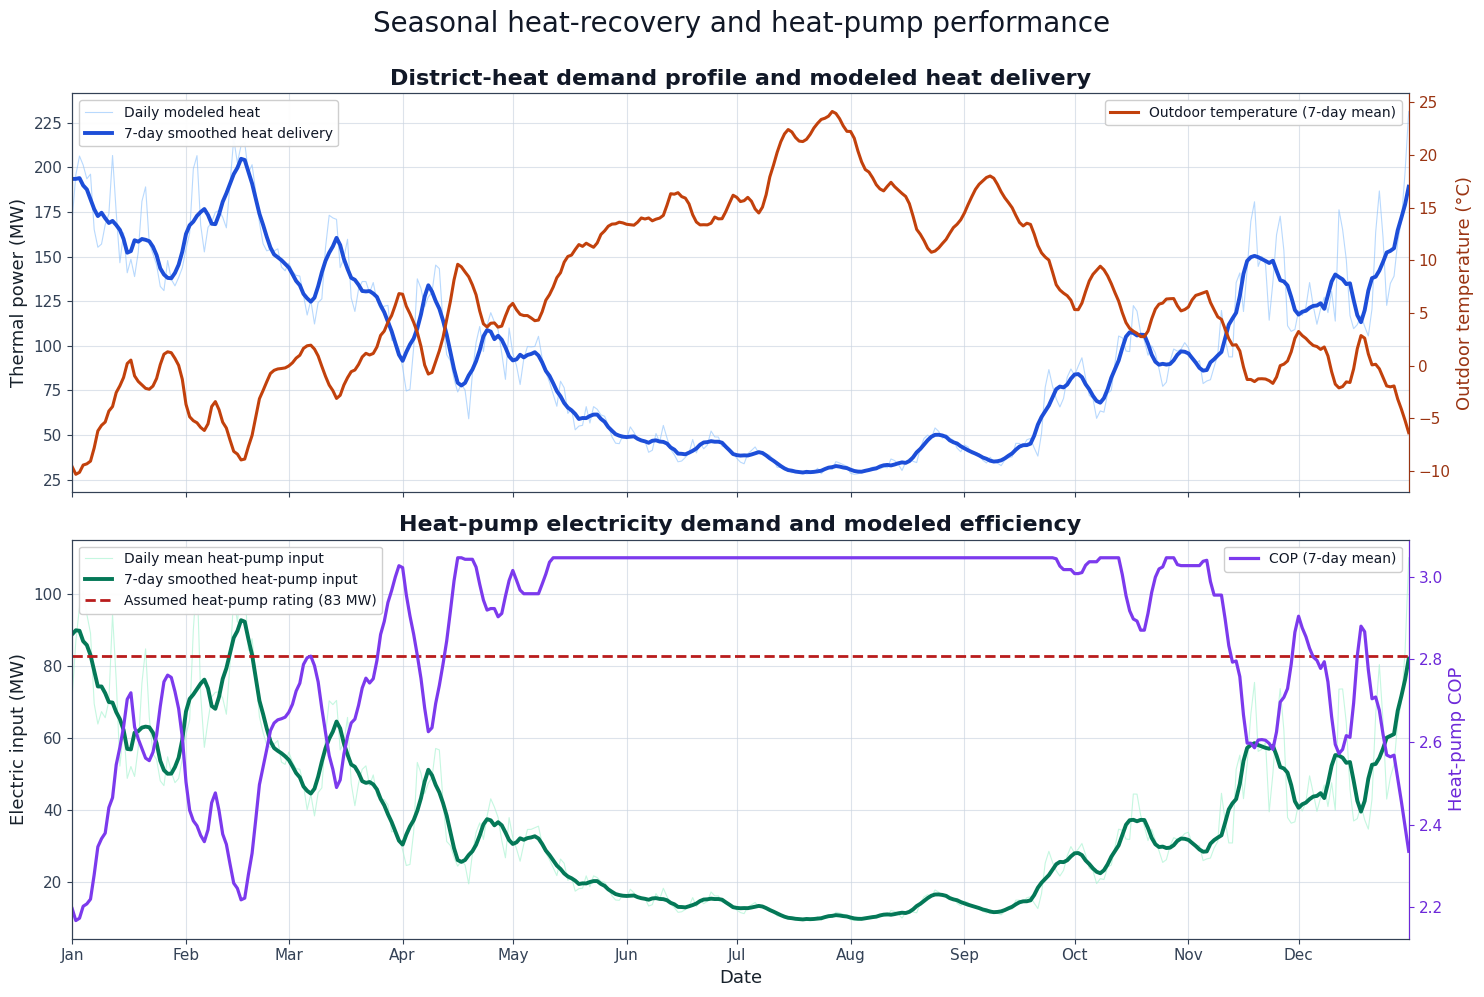

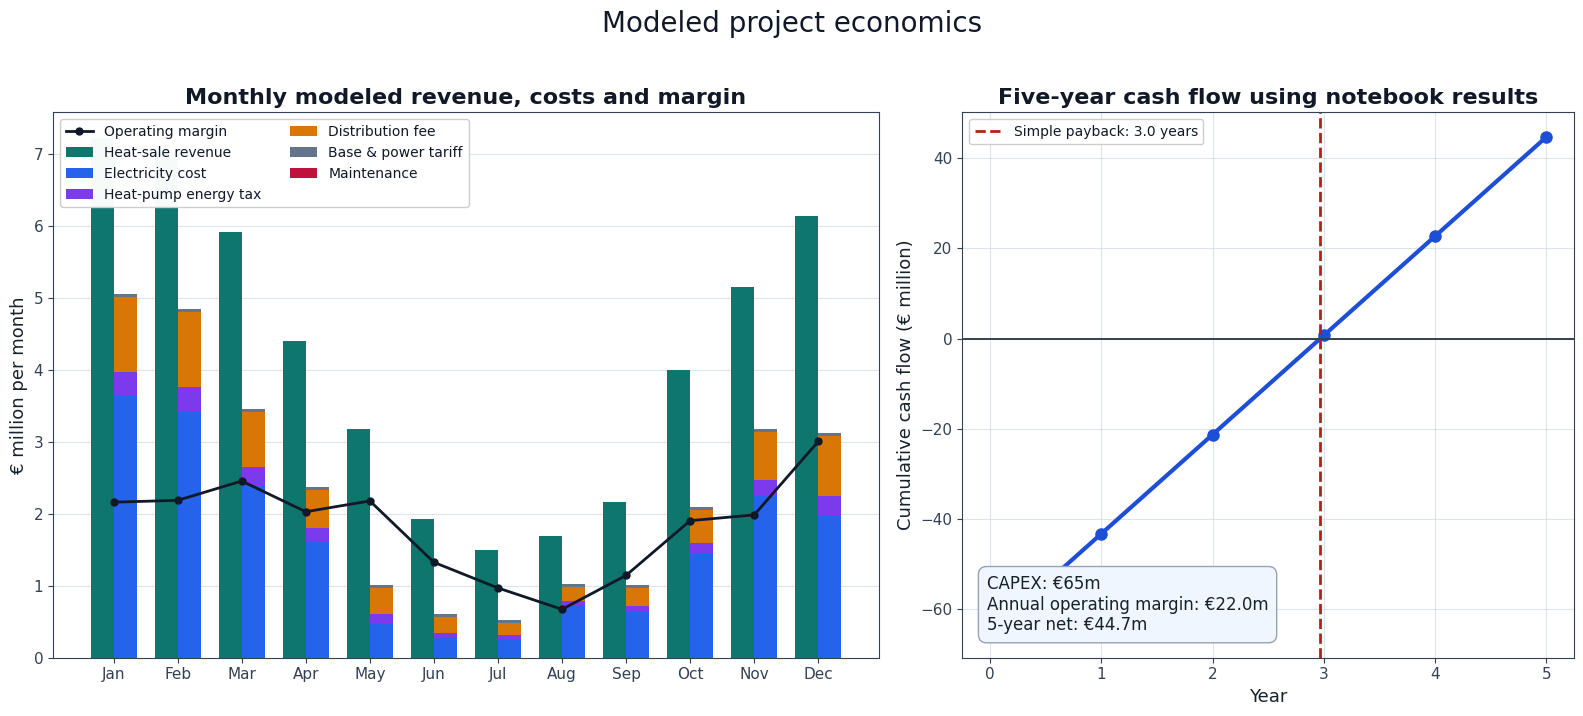

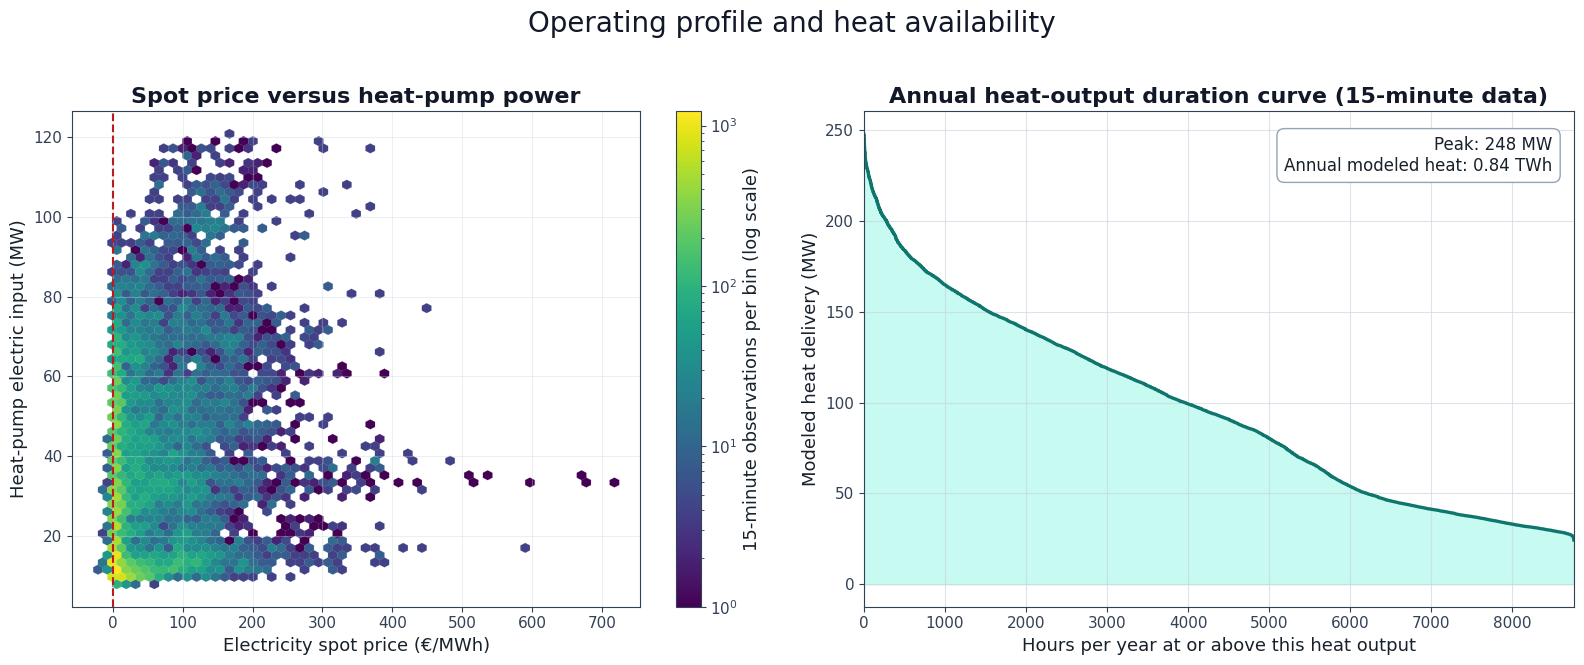

Annual heat sales: €50,315,440 | Modeled annual OPEX including maintenance: €28,293,448 | Five-year net after CAPEX: €44,723,293


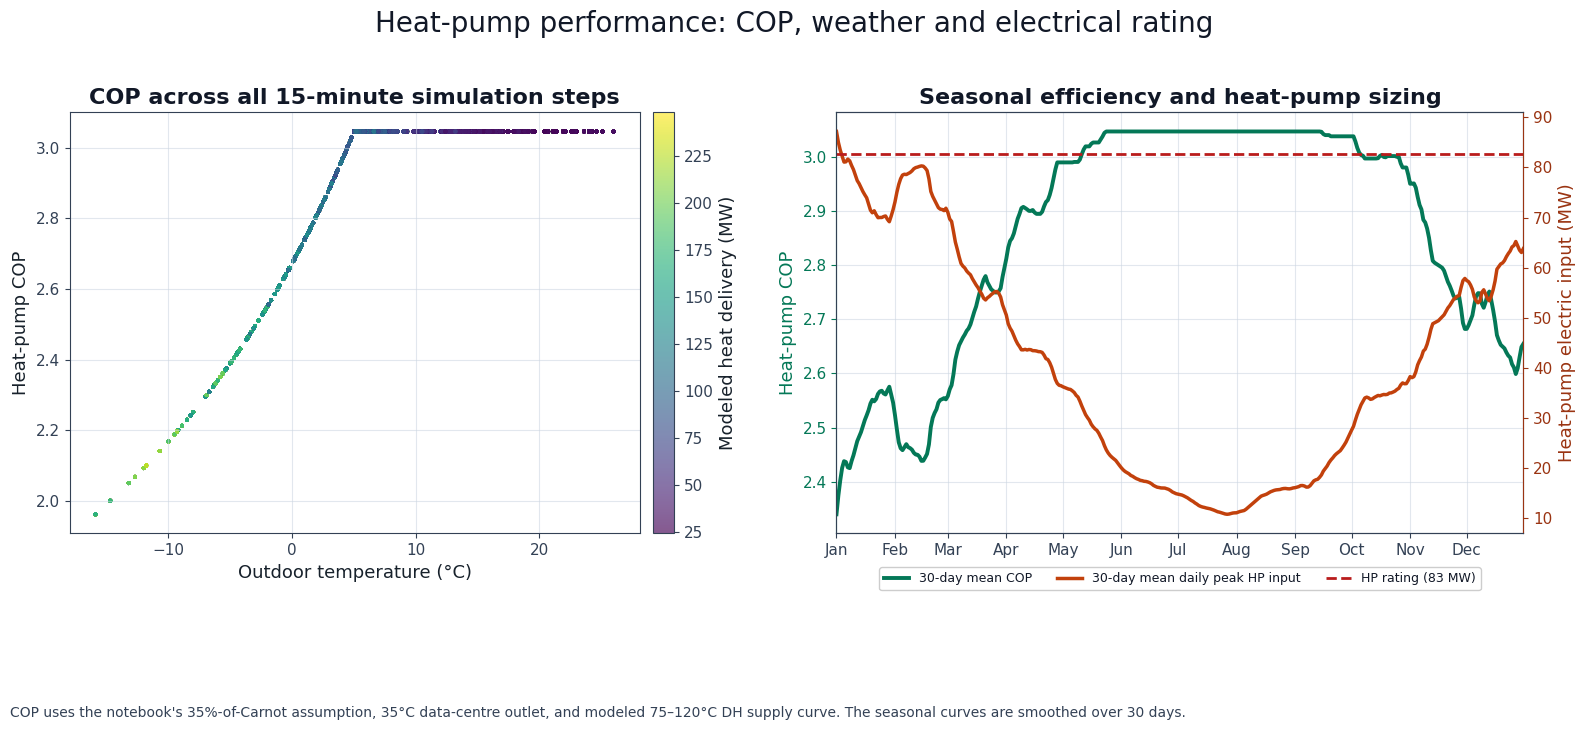

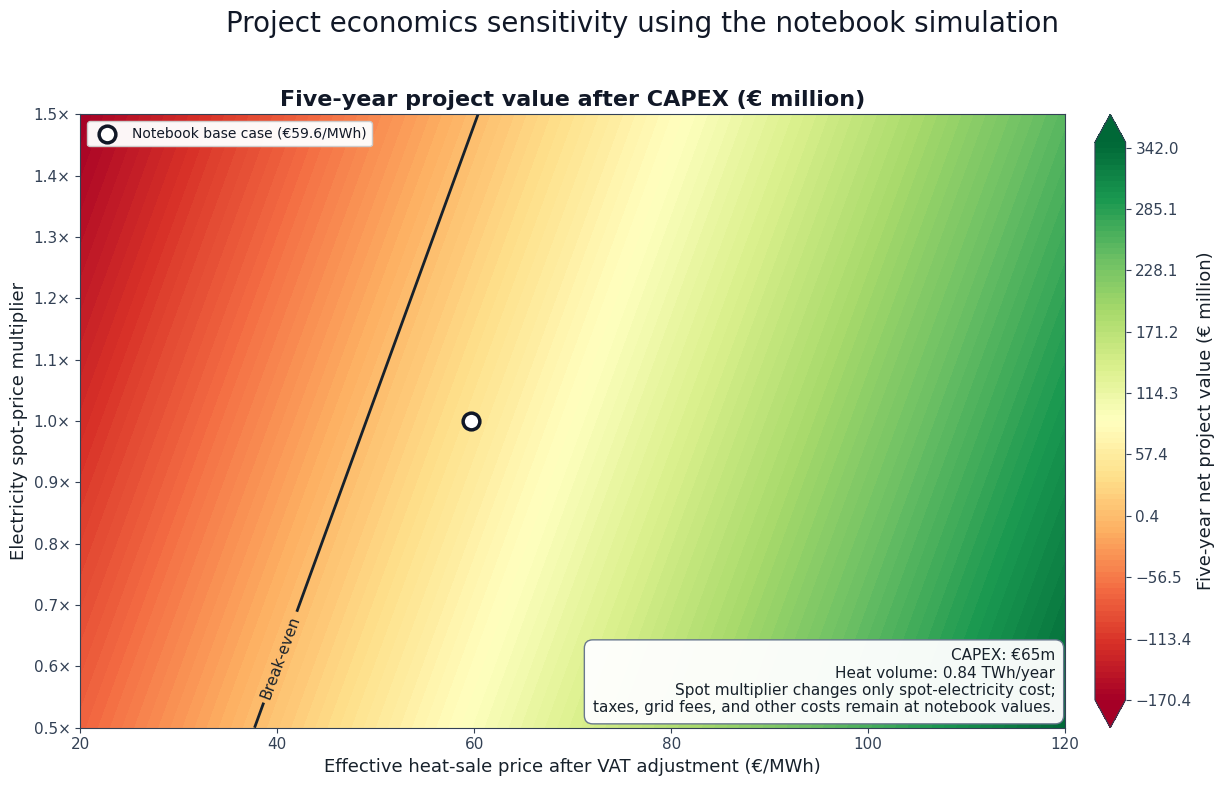

In [314]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np


plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#334155",
    "axes.labelcolor": "#17212b",
    "axes.titlecolor": "#111827",
    "text.color": "#111827",
    "xtick.color": "#334155",
    "ytick.color": "#334155",
    "grid.color": "#cbd5e1",
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "figure.titlesize": 20,
})

plot_data = pandas.DataFrame(data).set_index("datetime").sort_index()
plot_data["Heat sales revenue"] = (
    plot_data["heat consumed"] / 4 * DH_SALE_PRICE * (1 - VAT)
)
plot_data["Electricity cost"] = (
    plot_data["HP power"] / 4 * plot_data["spot price"]
)
plot_data["Heat-pump energy tax"] = (
    plot_data["HP power"] * TAX_E_HP * (1 + VAT)
)
distribution_fee = np.where(
    (plot_data.index.hour >= 7) & (plot_data.index.hour < 22),
    dist_fee_1,
    dist_fee_2,
)
plot_data["Distribution fee"] = plot_data["HP power"] / 4 * distribution_fee

weather = pandas.Series(
    pandas.to_numeric(Temp.iloc[:, 5]).to_numpy(),
    index=pandas.to_datetime(Temp["date"]),
)
daily = plot_data.resample("D").mean(numeric_only=True)
daily["Outdoor temperature"] = daily.index.normalize().map(weather)
daily_smooth = daily.rolling(7, center=True, min_periods=1).mean()

monthly = plot_data.resample("MS").agg({
    "heat consumed": "sum",
    "Heat sales revenue": "sum",
    "Electricity cost": "sum",
    "Heat-pump energy tax": "sum",
    "Distribution fee": "sum",
})
variable_cost_total = plot_data[
    ["Electricity cost", "Heat-pump energy tax", "Distribution fee"]
].sum().sum()
other_grid_fees = OPEX - variable_cost_total
monthly["Base & power tariff"] = other_grid_fees / 12
monthly["Maintenance"] = MAINTENANCE_COSTS / 12
monthly["Total costs"] = monthly[
    [
        "Electricity cost",
        "Heat-pump energy tax",
        "Distribution fee",
        "Base & power tariff",
        "Maintenance",
    ]
].sum(axis=1)
monthly["Operating margin"] = monthly["Heat sales revenue"] - monthly["Total costs"]
annual_margin = Revenue - opex

# Seasonal heat matching and modeled heat-pump operation
fig, (ax_heat, ax_hp) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
ax_heat.plot(
    daily.index,
    daily["heat consumed"],
    color="#93c5fd",
    linewidth=0.8,
    alpha=0.65,
    label="Daily modeled heat",
)
ax_heat.plot(
    daily_smooth.index,
    daily_smooth["heat consumed"],
    color="#1d4ed8",
    linewidth=2.8,
    label="7-day smoothed heat delivery",
)
ax_heat.set_ylabel("Thermal power (MW)")
ax_heat.grid(True, alpha=0.65)
ax_heat.legend(loc="upper left", frameon=True, framealpha=0.95)
ax_heat_right = ax_heat.twinx()
ax_heat_right.plot(
    daily_smooth.index,
    daily_smooth["Outdoor temperature"],
    color="#c2410c",
    linewidth=2.2,
    label="Outdoor temperature (7-day mean)",
)
ax_heat_right.set_ylabel("Outdoor temperature (°C)", color="#9a3412")
ax_heat_right.tick_params(axis="y", colors="#9a3412")
ax_heat_right.spines["right"].set_color("#9a3412")
ax_heat_right.legend(loc="upper right", frameon=True, framealpha=0.95)
ax_heat.set_title("District-heat demand profile and modeled heat delivery")
ax_hp.plot(
    daily.index,
    daily["HP power"],
    color="#a7f3d0",
    linewidth=0.8,
    alpha=0.65,
    label="Daily mean heat-pump input",
)
ax_hp.plot(
    daily_smooth.index,
    daily_smooth["HP power"],
    color="#047857",
    linewidth=2.8,
    label="7-day smoothed heat-pump input",
)
ax_hp.axhline(
    HP.power,
    color="#b91c1c",
    linestyle="--",
    linewidth=2,
    label=f"Assumed heat-pump rating ({HP.power:.0f} MW)",
)
ax_hp.set_ylabel("Electric input (MW)")
ax_hp.grid(True, alpha=0.65)
ax_hp.legend(loc="upper left", frameon=True, framealpha=0.95)
ax_hp_right = ax_hp.twinx()
ax_hp_right.plot(
    daily_smooth.index,
    daily_smooth["COP"],
    color="#7c3aed",
    linewidth=2.3,
    label="COP (7-day mean)",
)
ax_hp_right.set_ylabel("Heat-pump COP", color="#6d28d9")
ax_hp_right.tick_params(axis="y", colors="#6d28d9")
ax_hp_right.spines["right"].set_color("#6d28d9")
ax_hp_right.legend(loc="upper right", frameon=True, framealpha=0.95)
ax_hp.set_title("Heat-pump electricity demand and modeled efficiency")
ax_hp.set_xlabel("Date")
ax_hp.xaxis.set_major_locator(mdates.MonthLocator())
ax_hp.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_hp.set_xlim(daily.index.min(), daily.index.max())
fig.suptitle("Seasonal heat-recovery and heat-pump performance", y=0.995)
fig.tight_layout()
plt.show()
plt.close(fig)

# Monthly revenues and operating costs, plus the notebook's five-year cash flow
fig, (ax_month, ax_cash) = plt.subplots(
    1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.35, 1]}
)
month_x = np.arange(len(monthly))
bar_width = 0.36
ax_month.bar(
    month_x - bar_width / 2,
    monthly["Heat sales revenue"] / 1e6,
    bar_width,
    color="#0f766e",
    label="Heat-sale revenue",
)
cost_colors = {
    "Electricity cost": "#2563eb",
    "Heat-pump energy tax": "#7c3aed",
    "Distribution fee": "#d97706",
    "Base & power tariff": "#64748b",
    "Maintenance": "#be123c",
}
cost_bottom = np.zeros(len(monthly))
for cost, color in cost_colors.items():
    amount = monthly[cost].to_numpy() / 1e6
    ax_month.bar(
        month_x + bar_width / 2,
        amount,
        bar_width,
        bottom=cost_bottom,
        color=color,
        label=cost,
    )
    cost_bottom += amount
ax_month.plot(
    month_x,
    monthly["Operating margin"] / 1e6,
    color="#111827",
    marker="o",
    markersize=5,
    linewidth=2,
    label="Operating margin",
)
ax_month.set_xticks(month_x, monthly.index.strftime("%b"))
ax_month.set_ylabel("€ million per month")
ax_month.set_title("Monthly modeled revenue, costs and margin")
ax_month.grid(axis="y", alpha=0.65)
ax_month.set_axisbelow(True)
ax_month.legend(loc="upper left", ncol=2, frameon=True, framealpha=0.97)

years = np.arange(0, 6)
cumulative_cash_flow = -capex + years * annual_margin
ax_cash.plot(
    years,
    cumulative_cash_flow / 1e6,
    color="#1d4ed8",
    marker="o",
    linewidth=3,
    markersize=8,
)
ax_cash.axhline(0, color="#334155", linewidth=1.4)
if annual_margin > 0 and capex > 0:
    payback_years = capex / annual_margin
    ax_cash.axvline(
        payback_years,
        color="#b91c1c",
        linestyle="--",
        linewidth=2,
        label=f"Simple payback: {payback_years:.1f} years",
    )
    ax_cash.legend(loc="upper left", frameon=True, framealpha=0.97)
ax_cash.set_xticks(years)
ax_cash.set_xlabel("Year")
ax_cash.set_ylabel("Cumulative cash flow (€ million)")
ax_cash.set_title("Five-year cash flow using notebook results")
ax_cash.grid(True, alpha=0.65)
ax_cash.text(
    0.04,
    0.05,
    f"CAPEX: €{capex / 1e6:.0f}m\n"
    f"Annual operating margin: €{annual_margin / 1e6:.1f}m\n"
    f"5-year net: €{(-capex + 5 * annual_margin) / 1e6:.1f}m",
    transform=ax_cash.transAxes,
    fontsize=12,
    color="#17212b",
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "#eff6ff", "edgecolor": "#94a3b8"},
)
fig.suptitle("Modeled project economics", y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)

# Full 15-minute resolution for operating-price and annual-load curves
fig, (ax_price, ax_duration) = plt.subplots(1, 2, figsize=(16, 6.5))
price_hex = ax_price.hexbin(
    plot_data["spot price"],
    plot_data["HP power"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="viridis",
    linewidths=0.15,
)
colorbar = fig.colorbar(price_hex, ax=ax_price)
colorbar.set_label("15-minute observations per bin (log scale)")
ax_price.set_xlabel("Electricity spot price (€/MWh)")
ax_price.set_ylabel("Heat-pump electric input (MW)")
ax_price.set_title("Spot price versus heat-pump power")
ax_price.grid(True, alpha=0.35)
ax_price.axvline(0, color="#b91c1c", linestyle="--", linewidth=1.5)

duration = np.sort(plot_data["heat consumed"].to_numpy())[::-1]
duration_hours = np.arange(1, len(duration) + 1) / 4
ax_duration.plot(duration_hours, duration, color="#0f766e", linewidth=2.4)
ax_duration.fill_between(duration_hours, duration, color="#99f6e4", alpha=0.55)
ax_duration.set_xlim(0, duration_hours[-1])
ax_duration.set_xlabel("Hours per year at or above this heat output")
ax_duration.set_ylabel("Modeled heat delivery (MW)")
ax_duration.set_title("Annual heat-output duration curve (15-minute data)")
ax_duration.grid(True, alpha=0.65)
ax_duration.text(
    0.97,
    0.95,
    f"Peak: {duration[0]:.0f} MW\n"
    f"Annual modeled heat: {plot_data['heat consumed'].sum() / 4 / 1e6:.2f} TWh",
    transform=ax_duration.transAxes,
    ha="right",
    va="top",
    fontsize=12,
    color="#17212b",
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white", "edgecolor": "#94a3b8"},
)
fig.suptitle("Operating profile and heat availability", y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)

print(
    f"Annual heat sales: €{Revenue:,.0f} | "
    f"Modeled annual OPEX including maintenance: €{opex:,.0f} | "
    f"Five-year net after CAPEX: €{-capex + 5 * (Revenue - opex):,.0f}"
)

# Heat-pump performance and seasonal sizing, using every 15-minute simulation point
plot_data["Outdoor temperature"] = plot_data.index.normalize().map(weather)
plot_data["DH supply temperature"] = plot_data["Outdoor temperature"].map(DH_Temp)

fig, (ax_cop, ax_season) = plt.subplots(1, 2, figsize=(16, 7))
cop_points = ax_cop.scatter(
    plot_data["Outdoor temperature"],
    plot_data["COP"],
    c=plot_data["heat consumed"],
    cmap="viridis",
    s=8,
    alpha=0.65,
    linewidths=0,
    rasterized=True,
)
ax_cop.set_xlabel("Outdoor temperature (°C)")
ax_cop.set_ylabel("Heat-pump COP")
ax_cop.set_title("COP across all 15-minute simulation steps")
ax_cop.grid(True, alpha=0.55)
cop_colorbar = fig.colorbar(cop_points, ax=ax_cop, pad=0.02)
cop_colorbar.set_label("Modeled heat delivery (MW)")
cop_colorbar.ax.tick_params(labelsize=11)

daily_hp = plot_data.resample("D").agg(
    mean_cop=("COP", "mean"),
    peak_hp_power=("HP power", "max"),
)
seasonal = daily_hp.rolling(30, center=True, min_periods=1).mean()
season_x = seasonal.index
ax_season.plot(
    season_x,
    seasonal["mean_cop"],
    color="#047857",
    linewidth=2.8,
    label="30-day mean COP",
)
ax_season.set_ylabel("Heat-pump COP", color="#047857")
ax_season.tick_params(axis="y", colors="#047857")
ax_season.spines["left"].set_color("#047857")
ax_season.grid(True, alpha=0.55)
ax_season_right = ax_season.twinx()
ax_season_right.plot(
    season_x,
    seasonal["peak_hp_power"],
    color="#c2410c",
    linewidth=2.5,
    label="30-day mean daily peak HP input",
)
ax_season_right.axhline(
    HP.power,
    color="#b91c1c",
    linestyle="--",
    linewidth=2,
    label=f"HP rating ({HP.power:.0f} MW)",
)
ax_season_right.set_ylabel("Heat-pump electric input (MW)", color="#9a3412")
ax_season_right.tick_params(axis="y", colors="#9a3412")
ax_season_right.spines["right"].set_color("#9a3412")
ax_season.set_title("Seasonal efficiency and heat-pump sizing")
ax_season.xaxis.set_major_locator(mdates.MonthLocator())
ax_season.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_season.set_xlim(season_x.min(), season_x.max())
season_handles, season_labels = ax_season.get_legend_handles_labels()
right_handles, right_labels = ax_season_right.get_legend_handles_labels()
ax_season.legend(
    season_handles + right_handles,
    season_labels + right_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    fontsize=9,
    frameon=True,
    framealpha=0.97,
)
fig.suptitle(
    "Heat-pump performance: COP, weather and electrical rating",
    y=1.02,
)
fig.text(
    0.01,
    0.01,
    f"COP uses the notebook's {HP.efficiency:.0%}-of-Carnot assumption, "
    f"{DH_TEMP_DC:.0f}°C data-centre outlet, and modeled 75–120°C DH supply curve. "
    "The seasonal curves are smoothed over 30 days.",
    fontsize=10,
    color="#334155",
)
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.show()
plt.close(fig)

# Five-year project value over heat-sale price and electricity spot-price scenarios
heat_volume_mwh = plot_data["heat consumed"].sum() / 4
spot_electricity_cost = plot_data["Electricity cost"].sum()
other_annual_costs = opex - spot_electricity_cost
sale_prices = np.linspace(20, 120, 201)
spot_price_multipliers = np.linspace(0.5, 1.5, 201)
sale_grid, spot_multiplier_grid = np.meshgrid(sale_prices, spot_price_multipliers)
five_year_value_millions = (
    5
    * (
        heat_volume_mwh * sale_grid
        - spot_electricity_cost * spot_multiplier_grid
        - other_annual_costs
    )
    - capex
) / 1e6

fig, ax = plt.subplots(figsize=(13, 8))
levels = np.linspace(
    five_year_value_millions.min(),
    five_year_value_millions.max(),
    101,
)
heatmap = ax.contourf(
    sale_grid,
    spot_multiplier_grid,
    five_year_value_millions,
    levels=levels,
    cmap="RdYlGn",
    extend="both",
)
if five_year_value_millions.min() <= 0 <= five_year_value_millions.max():
    zero_contour = ax.contour(
        sale_grid,
        spot_multiplier_grid,
        five_year_value_millions,
        levels=[0],
        colors="#17212b",
        linewidths=2,
    )
    ax.clabel(zero_contour, fmt={0: "Break-even"}, inline=True, fontsize=11)

base_sale_price = Revenue / heat_volume_mwh
base_spot_multiplier = 1.0
ax.scatter(
    [base_sale_price],
    [base_spot_multiplier],
    s=145,
    marker="o",
    facecolors="white",
    edgecolors="#111827",
    linewidths=2.5,
    label=f"Notebook base case (€{base_sale_price:.1f}/MWh)",
    zorder=5,
)
ax.set_xlabel("Effective heat-sale price after VAT adjustment (€/MWh)")
ax.set_ylabel("Electricity spot-price multiplier")
ax.set_title("Five-year project value after CAPEX (€ million)")
ax.set_yticks(spot_price_multipliers[::20])
ax.set_yticklabels([f"{value:.1f}×" for value in spot_price_multipliers[::20]])
ax.grid(False)
ax.legend(loc="upper left", frameon=True, framealpha=0.97)
value_colorbar = fig.colorbar(heatmap, ax=ax, pad=0.025)
value_colorbar.set_label("Five-year net project value (€ million)")
value_colorbar.ax.tick_params(labelsize=11)
ax.text(
    0.99,
    0.02,
    f"CAPEX: €{capex / 1e6:.0f}m\n"
    f"Heat volume: {heat_volume_mwh / 1e6:.2f} TWh/year\n"
    "Spot multiplier changes only spot-electricity cost;\n"
    "taxes, grid fees, and other costs remain at notebook values.",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=11,
    color="#17212b",
    bbox={
        "boxstyle": "round,pad=0.55",
        "facecolor": "white",
        "edgecolor": "#64748b",
        "alpha": 0.96,
    },
)
fig.suptitle("Project economics sensitivity using the notebook simulation", y=0.98)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
plt.close(fig)
